In [1]:
print("Credit Default Risk Prediction System")


Credit Default Risk Prediction System


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn lightgbm shap hyperopt streamlit ucimlrepo joblib

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 600.9 kB/s eta 0:00:18
   - -----------------------------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import streamlit as st
import hyperopt

print("All libraries imported successfully!")

ImportError: DLL load failed while importing _liblinear: An Application Control policy has blocked this file.

In [5]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [6]:
import lightgbm
print("LightGBM working")

LightGBM working


In [7]:
import shap
print("SHAP working")

ImportError: DLL load failed while importing _liblinear: An Application Control policy has blocked this file.

In [2]:
import pandas as pd
print("Pandas: OK")

import numpy as np
print("NumPy: OK")

import lightgbm as lgb
print("LightGBM: OK")

import streamlit as st
print("Streamlit: OK")

import hyperopt
print("Hyperopt: OK")

Pandas: OK
NumPy: OK
LightGBM: OK
Streamlit: OK
Hyperopt: OK


In [9]:
import pandas as pd

df = pd.read_csv(r"/mnt/data/cs-training.csv")


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/cs-training.csv'

In [10]:
import pandas as pd

df = pd.read_csv(r"C:\Users\sande\Downloads\cs-training.csv")

In [11]:
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [12]:
df.shape

(150000, 12)

In [13]:
df.columns

Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='str')

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\sande\Downloads\Loan_default.csv\Loan_default.csv")

In [16]:
df.head()


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [17]:
df.shape


(255347, 18)

In [18]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='str')

In [19]:
selected_columns = [
    'Age',
    'Income',
    'LoanAmount',
    'CreditScore',
    'MonthsEmployed',
    'DTIRatio',
    'Default'
]

df = df[selected_columns].copy()

In [20]:
df.shape


(255347, 7)

In [21]:
df['Default'].value_counts()


Default
0    225694
1     29653
Name: count, dtype: int64

In [22]:
df['Default'].value_counts(normalize=True) * 100

Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64

In [24]:
%matplotlib inline

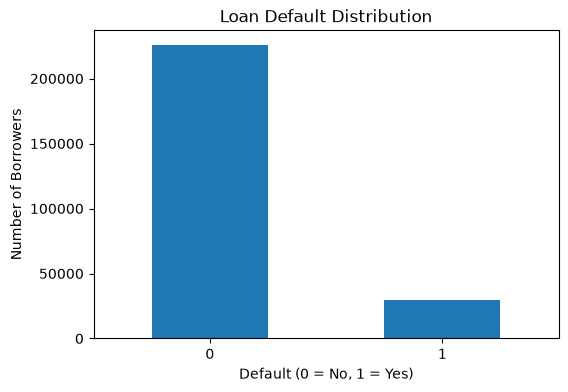

In [25]:
import matplotlib.pyplot as plt

df['Default'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('Loan Default Distribution')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Number of Borrowers')
plt.xticks(rotation=0)
plt.show()

In [26]:
df.isnull().sum()

Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
DTIRatio          0
Default           0
dtype: int64

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,0.900000,1.000000


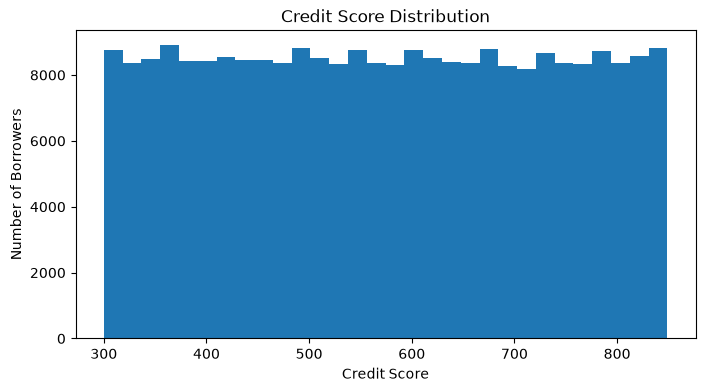

In [29]:
plt.figure(figsize=(8, 4))

plt.hist(df['CreditScore'], bins=30)

plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Number of Borrowers')

plt.show()

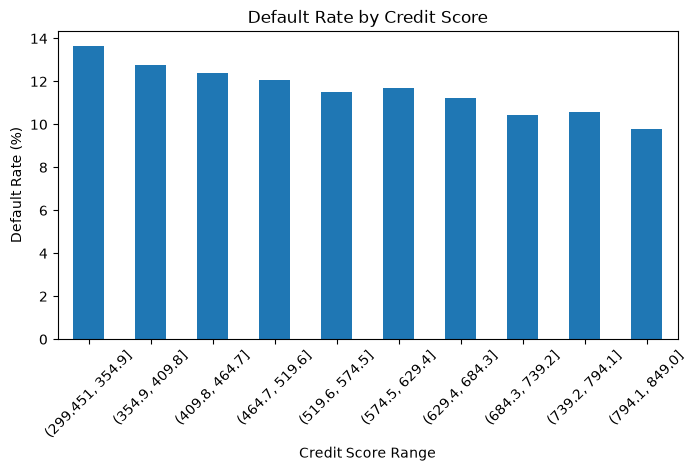

In [30]:
score_groups = pd.cut(df['CreditScore'], bins=10)

default_rate = df.groupby(score_groups, observed=False)['Default'].mean() * 100

default_rate.plot(kind='bar', figsize=(8, 4))

plt.title('Default Rate by Credit Score')
plt.xlabel('Credit Score Range')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.show()

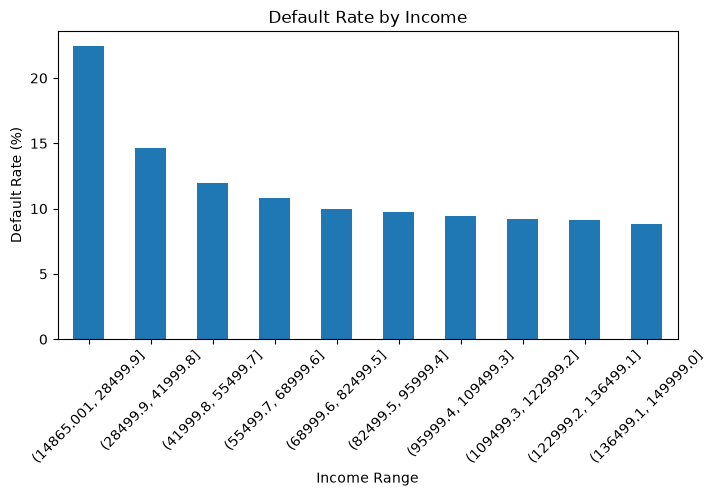

In [31]:
income_groups = pd.cut(df['Income'], bins=10)

income_default_rate = df.groupby(income_groups, observed=False)['Default'].mean() * 100

income_default_rate.plot(kind='bar', figsize=(8, 4))

plt.title('Default Rate by Income')
plt.xlabel('Income Range')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [4]:
income_groups = pd.cut(df['Income'], bins=10)

income_default_rate = df.groupby(income_groups, observed=False)['Default'].mean() * 100

income_default_rate.plot(kind='bar', figsize=(8, 4))

plt.title('Default Rate by Income')
plt.xlabel('Income Range')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.show()

NameError: name 'plt' is not defined

In [6]:
%matplotlib inline

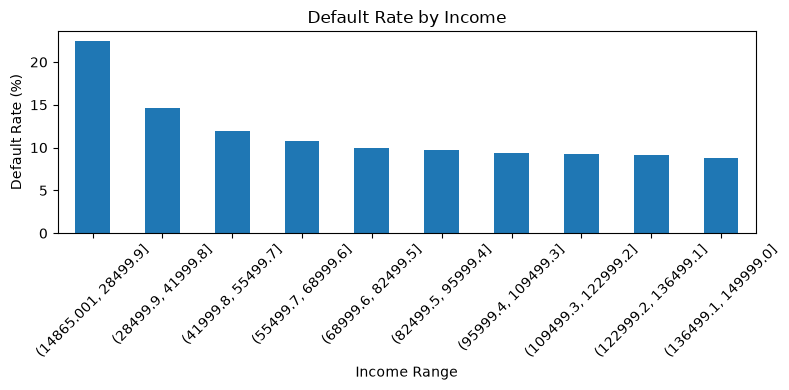

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

income_groups = pd.cut(df['Income'], bins=10)

income_default_rate = (
    df.groupby(income_groups, observed=False)['Default'].mean() * 100
)

income_default_rate.plot(kind='bar', figsize=(8, 4))

plt.title('Default Rate by Income')
plt.xlabel('Income Range')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [8]:
income_groups = pd.cut(df['Income'], bins=5)

income_analysis = df.groupby(income_groups, observed=False)['Default'].agg(
    ['count', 'mean']
)

income_analysis['mean'] = income_analysis['mean'] * 100

income_analysis

,count,mean
Income,,
"(14865.001, 41999.8]",51024,18.548134
"(41999.8, 68999.6]",50998,11.372995
"(68999.6, 95999.4]",51207,9.869744
"(95999.4, 122999.2]",51112,9.312882
"(122999.2, 149999.0]",51006,8.969533


In [9]:
loan_groups = pd.cut(df['LoanAmount'], bins=5)

loan_analysis = df.groupby(loan_groups, observed=False)['Default'].agg(
    ['count', 'mean']
)

loan_analysis['mean'] = loan_analysis['mean'] * 100

loan_analysis

,count,mean
LoanAmount,,
"(4755.001, 53999.8]",51197,8.053206
"(53999.8, 102999.6]",50944,9.665515
"(102999.6, 151999.4]",50869,11.191492
"(151999.4, 200999.2]",50927,13.344591
"(200999.2, 249999.0]",51410,15.788757


In [10]:
employment_groups = pd.cut(df['MonthsEmployed'], bins=5)

employment_analysis = df.groupby(
    employment_groups, observed=False
)['Default'].agg(['count', 'mean'])

employment_analysis['mean'] = employment_analysis['mean'] * 100

employment_analysis

,count,mean
MonthsEmployed,,
"(-0.119, 23.8]",50935,16.236380
"(23.8, 47.6]",51085,13.669375
"(47.6, 71.4]",50988,11.135954
"(71.4, 95.2]",51187,9.396917
"(95.2, 119.0]",51152,7.647795


In [11]:
dti_groups = pd.cut(df['DTIRatio'], bins=5)

dti_analysis = df.groupby(
    dti_groups, observed=False
)['Default'].agg(['count', 'mean'])

dti_analysis['mean'] = dti_analysis['mean'] * 100

dti_analysis

,count,mean
DTIRatio,,
"(0.0992, 0.26]",52484,10.578462
"(0.26, 0.42]",51238,11.241657
"(0.42, 0.58]",50835,11.795023
"(0.58, 0.74]",51221,12.188360
"(0.74, 0.9]",49569,12.310113


In [12]:
X = df.drop('Default', axis=1)
y = df['Default']

In [13]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (255347, 17)
y shape: (255347,)


In [14]:
print(X.columns.tolist())

['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


In [15]:
selected_columns = [
    'Age',
    'Income',
    'LoanAmount',
    'CreditScore',
    'MonthsEmployed',
    'DTIRatio',
    'Default'
]

df = df[selected_columns].copy()

print(df.shape)
print(df.columns.tolist())

(255347, 7)
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'DTIRatio', 'Default']


In [16]:
X = df.drop('Default', axis=1)
y = df['Default']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (255347, 6)
y shape: (255347,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (204277, 6)
X_test: (51070, 6)
y_train: (204277,)
y_test: (51070,)


In [19]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Default
0    88.387337
1    11.612663
Name: proportion, dtype: float64

Testing target distribution:
Default
0    88.386528
1    11.613472
Name: proportion, dtype: float64


In [20]:
from lightgbm import LGBMClassifier

model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    random_state=42,
    class_weight='balanced',
    verbosity=-1
)

In [21]:
model.fit(X_train, y_train)

,max_depth,7
,learning_rate,0.05
,n_estimators,300
,class_weight,'balanced'
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,min_split_gain,0.0


In [22]:
y_pred = model.predict(X_test)

print(y_pred[:20])

[0 0 0 0 1 0 1 0 1 1 1 0 1 0 0 0 0 0 0 1]


In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100)

Accuracy: 0.6692970432739377
Accuracy percentage: 66.92970432739376


In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[30364 14775]
 [ 2114  3817]]


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.67      0.78     45139
           1       0.21      0.64      0.31      5931

    accuracy                           0.67     51070
   macro avg       0.57      0.66      0.55     51070
weighted avg       0.85      0.67      0.73     51070



In [26]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance)


          Feature  Importance
2      LoanAmount        1811
1          Income        1663
3     CreditScore        1511
4  MonthsEmployed        1479
0             Age        1297
5        DTIRatio        1239


In [27]:
from sklearn.model_selection import train_test_split

X_train_tune, X_val, y_train_tune, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train_tune.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Training set: (163421, 6)
Validation set: (40856, 6)
Test set: (51070, 6)


In [28]:
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK

In [29]:
from hyperopt import hp

search_space = {
    'n_estimators': hp.choice('n_estimators', [200, 300, 500, 700]),
    'learning_rate': hp.loguniform('learning_rate', -3, -1.5),
    'max_depth': hp.choice('max_depth', [3, 5, 7, 9, -1]),
    'num_leaves': hp.choice('num_leaves', [15, 31, 50, 70]),
    'min_child_samples': hp.choice('min_child_samples', [20, 40, 60, 100]),
    'subsample': hp.uniform('subsample', 0.7, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.7, 1.0)
}

In [30]:
from hyperopt import STATUS_OK
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

def objective(params):

    model = LGBMClassifier(
        n_estimators=int(params['n_estimators']),
        learning_rate=params['learning_rate'],
        max_depth=int(params['max_depth']),
        num_leaves=int(params['num_leaves']),
        min_child_samples=int(params['min_child_samples']),
        subsample=params['subsample'],
        colsample_bytree=params['colsample_bytree'],
        class_weight='balanced',
        random_state=42,
        verbosity=-1
    )

    model.fit(X_train_tune, y_train_tune)

    y_val_pred = model.predict(X_val)

    score = f1_score(y_val, y_val_pred, pos_label=1)

    return {
        'loss': -score,
        'status': STATUS_OK,
        'f1': score
    }

In [31]:
import joblib

joblib.dump(model, "credit_risk_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC :", round(roc_auc_score(y_test, y_prob), 4))

Accuracy : 0.6693
Precision: 0.2053
Recall   : 0.6436
F1 Score: 0.3113
ROC-AUC : 0.7182


In [33]:

%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

model = joblib.load("credit_risk_model.pkl")

st.set_page_config(page_title="Credit Risk Predictor", page_icon="🏦", layout="wide")

st.title("🏦 Credit Default Risk Prediction")
st.caption("Machine Learning powered borrower risk assessment")

st.subheader("Borrower Information")

col1, col2 = st.columns(2)

with col1:
    age = st.number_input("Age", 18, 69, 30)
    income = st.number_input("Annual Income (₹)", 15000, 150000, 50000)
    loan_amount = st.number_input("Loan Amount (₹)", 5000, 250000, 50000)

with col2:
    credit_score = st.number_input("Credit Score", 300, 849, 600)
    months_employed = st.number_input("Months Employed", 0, 119, 24)
    dti_ratio = st.slider("Debt-to-Income Ratio", 0.10, 0.90, 0.30, 0.01)

if st.button("Predict Loan Risk", type="primary", use_container_width=True):

    input_data = pd.DataFrame([{
        "Age": age,
        "Income": income,
        "LoanAmount": loan_amount,
        "CreditScore": credit_score,
        "MonthsEmployed": months_employed,
        "DTIRatio": dti_ratio
    }])

    probability = model.predict_proba(input_data)[0][1]
    prediction = model.predict(input_data)[0]

    st.divider()
    st.subheader("Prediction Result")

    st.metric("Estimated Default Probability", f"{probability * 100:.2f}%")

    if probability < 0.30:
        st.success("LOW RISK")
    elif probability < 0.60:
        st.warning("MEDIUM RISK")
    else:
        st.error("HIGH RISK")

    if prediction == 1:
        st.error("Model Prediction: Potential Default")
    else:
        st.success("Model Prediction: Non-Default")

    st.progress(float(probability))

    st.info(
        "This prediction is generated by a machine learning model "
        "and should not be used as the sole basis for real lending decisions."
    )


Writing app.py


In [ ]:
!streamlit run app.py